### Implementação do Modelo de Baseline (Regressão Linear Múltipla)

#### I. Inicialmente, para finalizar de vez o tratamento, preciso olhar para os novos datasets processeds e entender onde estão os possíveis nulos ou os pequenos ajustes finais. Aqui, também quero tratar os outliers.

In [1]:
import pandas as pd

In [2]:
df_final = pd.read_csv("../data/processed/df_features.csv")
df_final.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,15
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0
dias_atrasados,0
order_item_id,0


O nome das categorias em PT-BR e em Inglês estavam nulos: apliquei o fillna para a limpeza deles.

In [3]:
df_final["product_category_name"] = df_final["product_category_name"].fillna("categoria_desconhecida")
df_final["product_category_name_english"] = df_final["product_category_name_english"].fillna("unknown_category")

df_final = df_final.dropna(subset=["product_weight_g", "payment_installments"])

df_final["distancia_km"] = df_final["distancia_km"].fillna(df_final["distancia_km"].mean())

df_final["taxa_atraso_vendedor"] = df_final["taxa_atraso_vendedor"].fillna(df_final["taxa_atraso_vendedor"].mean())

df_final.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,15
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0
dias_atrasados,0
order_item_id,0


-----------------------------------------------------------------------------------------------------

#### II. Encoding dos dados


In [4]:
df_final = pd.get_dummies(df_final, columns=["product_category_name_english", "payment_type"], drop_first=True)
df_final

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,dias_atrasados,order_item_id,product_id,seller_id,...,product_category_name_english_small_appliances,product_category_name_english_small_appliances_home_oven_and_coffee,product_category_name_english_sports_leisure,product_category_name_english_stationery,product_category_name_english_tablets_printing_image,product_category_name_english_telephony,product_category_name_english_toys,product_category_name_english_unknown_category,product_category_name_english_watches_gifts,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-7.107488,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,...,False,False,False,False,False,False,False,False,False,True,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-5.355729,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,...,False,False,False,False,False,False,False,False,False,False,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-17.245498,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,...,False,False,False,False,False,False,False,False,False,True,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-12.980069,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,...,False,False,False,False,False,False,False,False,False,True,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-9.238171,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,...,False,False,False,True,False,False,False,False,False,True,False,False
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,-5.543113,1,060cb19345d90064d1015407193c233d,8581055ce74af1daba164fdbd55a40de,...,False,False,False,False,False,False,False,False,False,True,False,False
6,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,-11.461215,1,4520766ec412348b8d4caa5e8a18c464,16090f2ca825584b5a147ab24aa30c86,...,False,False,False,False,False,False,False,False,False,True,False,False
7,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,-31.410995,1,ac1789e492dcd698c5c10b97a671243a,63b9ae557efed31d1f7687917d248a8d,...,False,False,False,False,False,False,False,False,False,False,False,False
8,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,-6.281597,1,9a78fb9862b10749a117f7fc3c31f051,7c67e1448b00f6e969d365cea6b010ab,...,False,False,False,False,False,False,False,False,False,True,False,False
9,e6ce16cb79ec1d90b1da9085a6118aeb,494dded5b201313c64ed7f100595b95c,delivered,2017-05-16 19:41:10,2017-05-16 19:50:18,2017-05-18 11:40:40,2017-05-29 11:18:31,2017-06-07,-8.528808,1,08574b074924071f4e201e151b152b4e,001cca7ae9ae17fb1caed9dfb1094831,...,False,False,False,False,False,False,False,False,False,True,False,False


-----------------------------------------------------------------------------------------------------

#### III. Deixando uma linha por pedido

A base que veio do 04 está no nível de **item**: um pedido com 3 produtos aparece 3 vezes, sempre com o mesmo `dias_atrasados`. Se eu treinar assim, os pedidos com mais itens pesam mais no modelo, e o mesmo pedido acaba contado várias vezes. Como o atraso é do pedido e não do item, faz mais sentido ter uma linha por `order_id`.

Para não perder informação dos itens, primeiro somo o que importa (preço, frete, peso, volume, quantidade de itens e de vendedores) e depois fico com a linha do item mais caro, que considero o "item principal" do pedido.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_final["order_purchase_timestamp"] = pd.to_datetime(df_final["order_purchase_timestamp"])
df_final["order_estimated_delivery_date"] = pd.to_datetime(df_final["order_estimated_delivery_date"])
df_final["volume_cm3"] = df_final["product_length_cm"] * df_final["product_height_cm"] * df_final["product_width_cm"]

agregado = df_final.groupby("order_id").agg(
    quantidade_itens_pedido=("order_item_id", "count"),
    vendedores_distintos=("seller_id", "nunique"),
    preco_total=("price", "sum"),
    frete_total=("freight_value", "sum"),
    peso_total_g=("product_weight_g", "sum"),
    volume_total_cm3=("volume_cm3", "sum"),
)

pedidos = (df_final.sort_values("price", ascending=False)
                   .drop_duplicates("order_id")
                   .set_index("order_id")
                   .join(agregado)
                   .reset_index())

print("Linhas antes (itens):", len(df_final))
print("Linhas agora (pedidos):", len(pedidos))

Linhas antes (itens): 110168
Linhas agora (pedidos): 96453


Algumas features que criamos no 04 (`janela_prometida`, `dia_semana_compra`, `epoca_alta_demanda`, `percentual_frete`) foram criadas **depois** do último `to_csv`, então não estão no `df_features.csv`. Recalculo aqui do mesmo jeito que fizemos lá.

Fica de nota para o grupo: vale colocar um `to_csv` no final do 04.

In [6]:
pedidos["janela_prometida"] = (pedidos["order_estimated_delivery_date"] - pedidos["order_purchase_timestamp"]).dt.total_seconds() / 86400
pedidos["dia_semana_compra"] = pedidos["order_purchase_timestamp"].dt.dayofweek
pedidos["epoca_alta_demanda"] = pedidos["order_purchase_timestamp"].dt.month.isin([11, 12]).astype(int)
pedidos["percentual_frete"] = pedidos["frete_total"] / pedidos["preco_total"] * 100
pedidos["cross_state"] = pedidos["cross_state"].astype(int)

pedidos[["janela_prometida", "dia_semana_compra", "epoca_alta_demanda", "percentual_frete"]].describe()

,janela_prometida,dia_semana_compra,epoca_alta_demanda,percentual_frete
count,96453.000000,96453.000000,96453.000000,96453.000000
mean,23.735605,2.756317,0.132728,30.836883
std,8.761258,1.966955,0.339282,31.163268
min,2.008009,0.000000,0.000000,0.000000
25%,18.328970,1.000000,0.000000,13.201553
50%,23.230289,3.000000,0.000000,22.437396
75%,28.407187,4.000000,0.000000,38.043728
max,155.135463,6.000000,1.000000,2144.705882


-----------------------------------------------------------------------------------------------------

#### IV. Escolhendo as variáveis (e cuidando do vazamento)

Esse foi o ponto que mais pensei. A pergunta do projeto é prever o atraso **no momento da compra**, então só posso usar o que já se sabe nesse momento. Se eu usar algo que só existe depois, o modelo vai parecer ótimo no teste e não serviria para nada na prática.

**Ficam de fora (vazamento):**
* `review_score` e `tem_comentario`: a avaliação só existe depois da entrega e, inclusive, é influenciada pelo atraso.
* `atraso_relativo`: é calculada a partir do próprio `dias_atrasados`, ou seja, é o alvo disfarçado.
* `atraso_despacho_combinado`, `order_approved_at`, `order_delivered_carrier_date` e `order_delivered_customer_date`: são datas que acontecem depois da compra.

**Ficam de fora (pouco úteis ou repetidas):** IDs, cidades, CEPs, latitude e longitude (a distância já resume essa informação) e tamanho de nome e descrição do produto.

**Entram:**

In [7]:
alvo = "dias_atrasados"

numericas = [
    "janela_prometida",          # prazo que o cliente recebeu
    "distancia_km",              # distância vendedor -> cliente
    "cross_state",               # vendedor em outro estado
    "taxa_atraso_vendedor",      # histórico de atraso do vendedor (só pedidos anteriores)
    "volume_historico_vendedor", # experiência do vendedor
    "preco_total", "frete_total", "percentual_frete",
    "peso_total_g", "volume_total_cm3",
    "quantidade_itens_pedido", "vendedores_distintos",
    "payment_installments",
    "dia_semana_compra", "epoca_alta_demanda",
]
dummies = [c for c in pedidos.columns
           if c.startswith("product_category_name_english_") or c.startswith("payment_type_")]
estados = ["customer_state", "seller_state"]  # viram dummies mais pra frente

print(len(numericas), "numéricas +", len(dummies), "dummies de categoria/pagamento + estados")

15 numéricas + 74 dummies de categoria/pagamento + estados


-----------------------------------------------------------------------------------------------------

#### V. Outliers

No começo do notebook eu quis tratar os outliers, então agora é a hora. Olhando o alvo, a maior parte dos pedidos chega de 6 a 16 dias **antes** do prazo, mas existem casos extremos dos dois lados: pedidos que chegaram mais de 140 dias antes do prometido e atrasos de mais de 180 dias.

Pedidos fora do IQR: 4870 (5.0%)


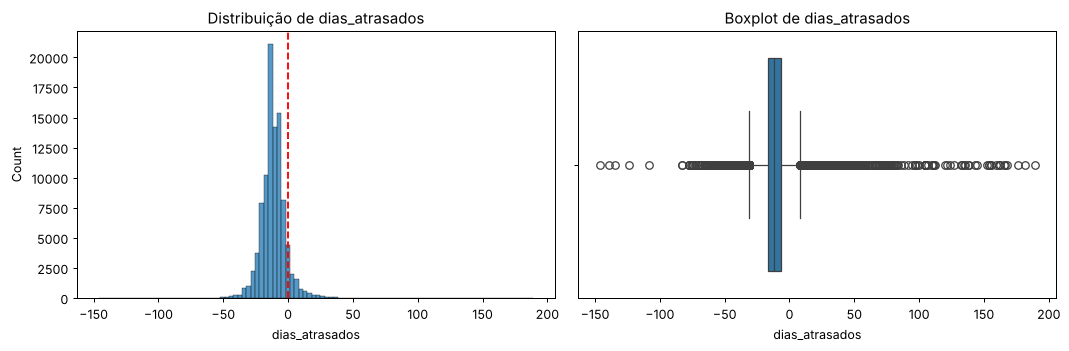

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pedidos[alvo], bins=100, ax=axes[0])
axes[0].set_title("Distribuição de dias_atrasados")
axes[0].axvline(0, color="red", linestyle="--")
sns.boxplot(x=pedidos[alvo], ax=axes[1])
axes[1].set_title("Boxplot de dias_atrasados")
plt.tight_layout()
plt.show()

Q1 = pedidos[alvo].quantile(0.25)
Q3 = pedidos[alvo].quantile(0.75)
IQR = Q3 - Q1
fora = ((pedidos[alvo] < Q1 - 1.5 * IQR) | (pedidos[alvo] > Q3 + 1.5 * IQR)).sum()
print(f"Pedidos fora do IQR: {fora} ({fora / len(pedidos):.1%})")

Excluir esses pedidos não me parece certo, porque os atrasos grandes são justamente o que mais incomoda o cliente. Então decidi:

1. **No alvo:** limitar (`clip`) entre os percentis 1% e 99%, **só no treino**. A regressão linear usa erro quadrático, então meia dúzia de atrasos de 150 dias puxam a reta inteira. No teste não mexo em nada, para a avaliação ser honesta.
2. **Nas features:** preço, frete, peso, volume e distância têm uma cauda longa à direita (aquilo que vimos na EDA aprofundada com o frete). Aplico `log1p` nelas, o que deixa a relação mais "linear" e diminui o peso dos extremos sem jogar dados fora.

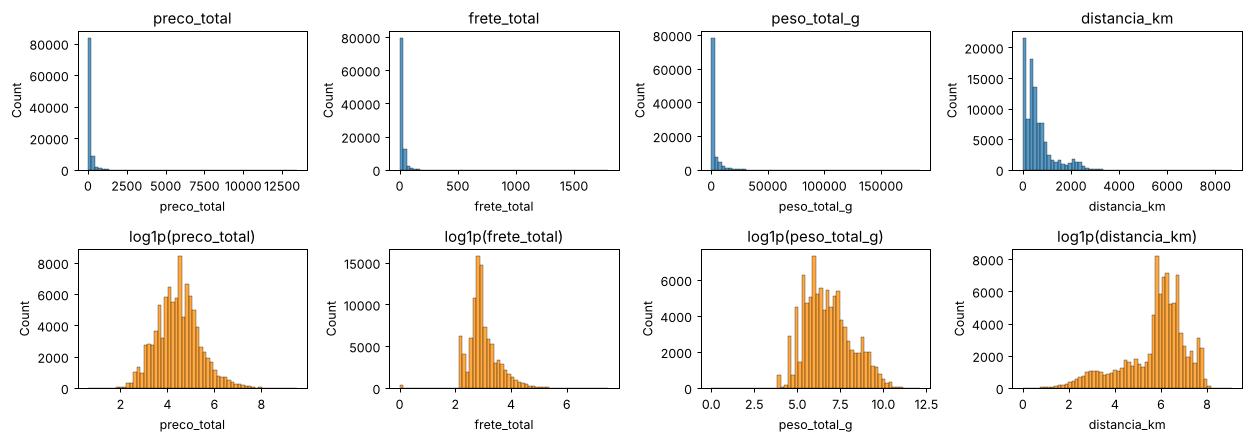

In [9]:
assimetricas = ["preco_total", "frete_total", "percentual_frete", "peso_total_g",
                "volume_total_cm3", "distancia_km", "volume_historico_vendedor"]

fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, col in zip(axes.flat, ["preco_total", "frete_total", "peso_total_g", "distancia_km"]):
    sns.histplot(pedidos[col], bins=60, ax=ax)
    ax.set_title(col)
for ax, col in zip(axes.flat[4:], ["preco_total", "frete_total", "peso_total_g", "distancia_km"]):
    sns.histplot(np.log1p(pedidos[col]), bins=60, ax=ax, color="darkorange")
    ax.set_title(f"log1p({col})")
plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------------------------------

#### VI. Separando treino e teste pelo tempo

Na EDA aprofundada vimos que o número de pedidos e o atraso mudam bastante de mês para mês (pico em nov/2017, Black Friday). Por isso não fiz `train_test_split` aleatório: misturaria pedidos do "futuro" no treino. Em vez disso:

* **Treino:** compras até março/2018
* **Teste:** compras de abril a agosto/2018

Assim o modelo prevê pedidos que aconteceram depois dos que ele viu, como seria na vida real.

In [10]:
corte = "2018-04-01"
treino = pedidos[pedidos["order_purchase_timestamp"] < corte].copy()
teste = pedidos[pedidos["order_purchase_timestamp"] >= corte].copy()

print(f"Treino: {len(treino)} pedidos | média de dias_atrasados: {treino[alvo].mean():.2f} | % atrasados: {(treino[alvo] > 0).mean():.1%}")
print(f"Teste:  {len(teste)} pedidos | média de dias_atrasados: {teste[alvo].mean():.2f} | % atrasados: {(teste[alvo] > 0).mean():.1%}")

Treino: 64303 pedidos | média de dias_atrasados: -10.75 | % atrasados: 9.2%
Teste:  32150 pedidos | média de dias_atrasados: -12.03 | % atrasados: 6.0%


O teste tem bem menos atrasos que o treino, porque fev/mar de 2018 foram meses ruins. Isso deixa a tarefa mais difícil para o modelo, mas é a situação real.

Agora monto o X e o y: log nas colunas assimétricas e estados virando dummies. Os nulos de `distancia_km` e `taxa_atraso_vendedor` já foram preenchidos lá no item I; o `fillna` aqui fica só como garantia, caso a base mude.

In [11]:
def monta_X(base, medias):
    X = base[numericas + dummies + estados].copy()
    for col, media in medias.items():
        X[col] = X[col].fillna(media)
    for col in assimetricas:
        X[col] = np.log1p(X[col])
    return X

medias_treino = treino[["distancia_km", "taxa_atraso_vendedor"]].mean().to_dict()
X_treino = monta_X(treino, medias_treino)
X_teste = monta_X(teste, medias_treino)

# dummies dos estados com as mesmas colunas no treino e no teste
X_treino = pd.get_dummies(X_treino, columns=estados, drop_first=True, dtype=float)
X_teste = pd.get_dummies(X_teste, columns=estados, drop_first=True, dtype=float)
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0)
X_treino = X_treino.astype(float)
X_teste = X_teste.astype(float)

limite_inf, limite_sup = treino[alvo].quantile([0.01, 0.99])
y_treino = treino[alvo].clip(limite_inf, limite_sup)
y_teste = teste[alvo]  # teste fica intacto

print(f"Alvo do treino limitado entre {limite_inf:.1f} e {limite_sup:.1f} dias")
print("X_treino:", X_treino.shape, "| X_teste:", X_teste.shape)

Alvo do treino limitado entre -34.4 e 21.9 dias
X_treino: (64303, 136) | X_teste: (32150, 136)


-----------------------------------------------------------------------------------------------------

#### VII. Multicolinearidade (VIF)

Regressão linear múltipla tem um pressuposto chato: as variáveis explicativas não podem ser muito correlacionadas entre si. Quando são, os coeficientes ficam instáveis e perdem o sentido. Uso o **VIF** (Variance Inflation Factor). Para cada variável, ajusto uma regressão dela contra todas as outras numéricas, e VIF = 1 / (1 − R²). Acima de 10 já é sinal de problema.

In [12]:
from sklearn.linear_model import LinearRegression

def calcula_vif(X):
    resultado = {}
    for col in X.columns:
        outras = X.drop(columns=col)
        r2 = LinearRegression().fit(outras, X[col]).score(outras, X[col])
        resultado[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(resultado).sort_values(ascending=False)

vif = calcula_vif(X_treino[numericas])
vif.to_frame("VIF")

,VIF
preco_total,593.353290
percentual_frete,457.187355
frete_total,197.709434
peso_total_g,3.348417
distancia_km,2.764123
volume_total_cm3,2.560486
cross_state,2.331483
janela_prometida,1.594861
quantidade_itens_pedido,1.499194
payment_installments,1.210654


Como eu desconfiava, `preco_total`, `frete_total` e `percentual_frete` explodiram. Faz sentido: depois do log, o percentual de frete é praticamente log(frete) − log(preço), então uma é combinação das outras duas. Tiro o `percentual_frete` (a informação continua lá, via preço e frete) e calculo de novo:

In [13]:
numericas.remove("percentual_frete")
X_treino = X_treino.drop(columns="percentual_frete")
X_teste = X_teste.drop(columns="percentual_frete")

calcula_vif(X_treino[numericas]).to_frame("VIF")

,VIF
frete_total,3.339239
peso_total_g,3.304512
distancia_km,2.762586
volume_total_cm3,2.556564
cross_state,2.331274
preco_total,1.710879
janela_prometida,1.594802
quantidade_itens_pedido,1.496222
payment_installments,1.203623
vendedores_distintos,1.074197


Agora todas ficaram abaixo de 5. Problema resolvido.

-----------------------------------------------------------------------------------------------------

#### VIII. Treinando a Regressão Linear Múltipla

Padronizo as variáveis (média 0, desvio 1) antes de treinar. Para a previsão em si não faz diferença, mas assim os coeficientes ficam comparáveis entre si: cada um passa a dizer quantos dias o atraso muda quando a variável aumenta um desvio-padrão.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)  # fit só no treino
X_teste_esc = scaler.transform(X_teste)

modelo = LinearRegression()
modelo.fit(X_treino_esc, y_treino)

previsao_teste = modelo.predict(X_teste_esc)
previsao_treino = modelo.predict(X_treino_esc)
print("Intercepto:", round(modelo.intercept_, 3))

Intercepto: -10.852


-----------------------------------------------------------------------------------------------------

#### IX. Avaliação

Uso três métricas:
* **MAE:** em média, quantos dias o modelo erra. É a mais fácil de explicar.
* **RMSE:** parecida, mas pune mais os erros grandes.
* **R²:** quanto da variação do atraso o modelo explica (0 = nada, 1 = tudo).

Para saber se o modelo presta, comparo com o "modelo burro" que sempre chuta a média do treino. Qualquer modelo útil precisa ganhar dele.

In [15]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def metricas(y_real, y_prev):
    return {"MAE (dias)": mean_absolute_error(y_real, y_prev),
            "RMSE (dias)": root_mean_squared_error(y_real, y_prev),
            "R²": r2_score(y_real, y_prev)}

chute_media = np.full(len(y_teste), y_treino.mean())

resultados = pd.DataFrame({
    "Chute da média": metricas(y_teste, chute_media),
    "Regressão Linear (treino)": metricas(treino[alvo], previsao_treino),
    "Regressão Linear (teste)": metricas(y_teste, previsao_teste),
}).T
resultados.round(3)

,MAE (dias),RMSE (dias),R²
Chute da média,7.015,9.394,-0.016
Regressão Linear (treino),5.449,8.903,0.290
Regressão Linear (teste),5.407,7.184,0.406


E como o tema é **atraso**, também vale olhar se o modelo acerta a pergunta "vai atrasar ou não?" (previsão > 0):

In [16]:
from sklearn.metrics import roc_auc_score

atrasou_real = (y_teste > 0).astype(int)
atrasou_prev = (previsao_teste > 0).astype(int)

print(f"Atrasos reais no teste: {atrasou_real.sum()}")
print(f"Atrasos que o modelo previu: {atrasou_prev.sum()}")
print(f"Atrasos reais que o modelo pegou: {(atrasou_real & atrasou_prev).sum()}")
print(f"ROC-AUC usando a previsão como 'risco': {roc_auc_score(atrasou_real, previsao_teste):.3f}")

Atrasos reais no teste: 1936
Atrasos que o modelo previu: 1257
Atrasos reais que o modelo pegou: 302
ROC-AUC usando a previsão como 'risco': 0.754


-----------------------------------------------------------------------------------------------------

#### X. Entendendo o modelo

##### Coeficientes

Um ponto forte da regressão linear é que dá para abrir a caixa e ver o que ela aprendeu. Positivo empurra para atraso, negativo para entrega adiantada.

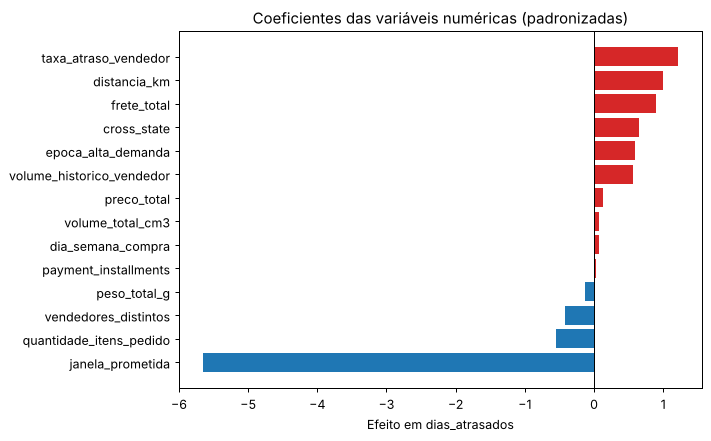

In [17]:
coeficientes = pd.Series(modelo.coef_, index=X_treino.columns)

coef_numericas = coeficientes[numericas].sort_values()
plt.figure(figsize=(8, 5))
cores = ["tab:red" if c > 0 else "tab:blue" for c in coef_numericas]
plt.barh(coef_numericas.index, coef_numericas.values, color=cores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes das variáveis numéricas (padronizadas)")
plt.xlabel("Efeito em dias_atrasados")
plt.tight_layout()
plt.show()

In [18]:
estados_cliente = coeficientes[coeficientes.index.str.startswith("customer_state_")].sort_values()
print("Estados do cliente que mais puxam para atraso (em relação ao AC, a categoria de referência):")
print(estados_cliente.tail(5).round(2).to_string())
print("\nE os que menos puxam:")
print(estados_cliente.head(5).round(2).to_string())

Estados do cliente que mais puxam para atraso (em relação ao AC, a categoria de referência):
customer_state_CE    0.44
customer_state_PA    0.45
customer_state_AL    0.49
customer_state_BA    0.50
customer_state_RJ    0.78

E os que menos puxam:
customer_state_SP   -0.49
customer_state_MG   -0.40
customer_state_PR   -0.22
customer_state_DF   -0.05
customer_state_RO   -0.03


##### Resíduos

Outro pressuposto da regressão linear é que os erros (resíduos) se espalhem de forma parecida em torno de zero. Vamos ver:

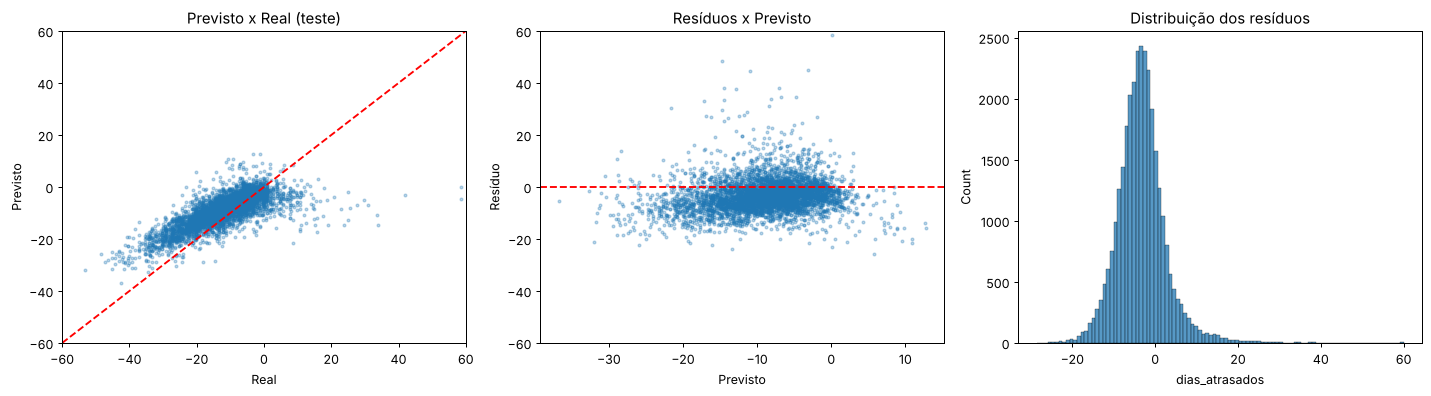

In [19]:
residuos = y_teste - previsao_teste

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

amostra = np.random.default_rng(42).choice(len(y_teste), 5000, replace=False)
axes[0].scatter(y_teste.values[amostra], previsao_teste[amostra], s=5, alpha=0.3)
axes[0].plot([-60, 60], [-60, 60], color="red", linestyle="--")
axes[0].set_xlim(-60, 60); axes[0].set_ylim(-60, 60)
axes[0].set_xlabel("Real"); axes[0].set_ylabel("Previsto")
axes[0].set_title("Previsto x Real (teste)")

axes[1].scatter(previsao_teste[amostra], residuos.values[amostra], s=5, alpha=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_ylim(-60, 60)
axes[1].set_xlabel("Previsto"); axes[1].set_ylabel("Resíduo")
axes[1].set_title("Resíduos x Previsto")

sns.histplot(residuos.clip(-40, 60), bins=100, ax=axes[2])
axes[2].set_title("Distribuição dos resíduos")

plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------------------------------

#### XI. Salvando para os próximos notebooks

Salvo a base já no nível de pedido e os resultados do baseline. Assim, o próximo notebook (Random Forest, XGBoost, KNN e SVR) parte exatamente dos mesmos dados e do mesmo corte de tempo, e a comparação fica justa.

In [20]:
colunas_salvar = ["order_id", "order_purchase_timestamp", alvo] + numericas + ["percentual_frete"] + dummies + estados
pedidos[colunas_salvar].to_csv("../data/processed/df_modelo.csv", index=False)
resultados.round(4).to_csv("../data/processed/resultados_baseline.csv")
print("Salvos: df_modelo.csv e resultados_baseline.csv")

Salvos: df_modelo.csv e resultados_baseline.csv


-----------------------------------------------------------------------------------------------------

#### XII. Conclusões do baseline

Resumindo o que tirei desse baseline:

* **O modelo funciona e ganha bem do chute da média.** No teste, a regressão linear erra em média **5,4 dias** (MAE), contra 7,0 dias de quem chuta sempre a média. São 23% a menos de erro, com **R² ≈ 0,41**. Esse é o número que os próximos modelos (Random Forest, XGBoost, KNN e SVR) precisam bater.

* **O R² do treino (0,29) ficou menor que o do teste (0,41).** Parece estranho, mas tem explicação. O treino inclui fev/mar de 2018, os piores meses de atraso da base, e eu meço o erro no alvo original, sem o clip. O teste (abr–ago/2018) foi um período mais tranquilo. Não é sinal de overfitting, é o próprio dado mudando com o tempo.

* **O prazo prometido é, de longe, a variável mais forte.** Quanto maior a `janela_prometida`, mais adiantada a entrega costuma chegar (coeficiente de −5,7). Isso mostra que a Olist põe uma folga grande nos prazos longos. Depois dela vêm o **histórico de atraso do vendedor**, a **distância**, o **frete**, o vendedor ser de **outro estado** e a **época de Black Friday/Natal**, todos empurrando para atraso, como a EDA já indicava.

* **A região também pesa.** Clientes do RJ, BA, AL, PA e CE puxam a previsão para atraso, e SP, MG e PR para o lado oposto. Isso bate com o que vimos na EDA aprofundada sobre a desigualdade logística.

* **Uma surpresa:** `quantidade_itens_pedido` saiu com coeficiente negativo (mais itens → chega mais cedo). Eu esperava o contrário. Pode ser efeito de outras variáveis junto (pedidos maiores costumam ter prazo maior), mas vale investigar.

* **Para a pergunta "vai atrasar ou não?", o modelo é fraco.** Ele pegou só 302 dos 1.936 atrasos do teste usando a regra previsão > 0. Ainda assim, a previsão ordena bem o risco (ROC-AUC de 0,75), então um limiar diferente de zero já ajudaria.

* **Os resíduos mostram o limite da regressão linear.** No gráfico previsto x real, o modelo "achata" as previsões: subestima os atrasos grandes e superestima as entregas muito adiantadas. Isso mostra que a relação não é totalmente linear, o que justifica testar modelos não lineares a seguir.

**Pontos de atenção para o grupo:**
1. A `taxa_atraso_vendedor` usa os pedidos anteriores do vendedor, mas alguns deles podem ainda não ter sido entregues no momento da compra. É um vazamento pequeno, mas vale citar no relatório (ou calcular a taxa só com pedidos já entregues até a data da compra).
2. No 04, as últimas features não estão sendo salvas no CSV. Coloquei o recálculo aqui, mas o ideal é corrigir lá.
3. No item I, preenchi `distancia_km` e `taxa_atraso_vendedor` com a média da base inteira, o que inclui o período de teste. Como são poucos casos (cerca de 0,5% e 3% das linhas), o efeito é mínimo, mas o correto seria usar a média só do treino.